<a href="https://colab.research.google.com/github/Tejaswini2028/CSA4703-Deep-Learning/blob/main/exp%2021%20to%2030.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 21 – Factor Analysis and Latent Factor Interpretation

        Pay  Workload  Manager Support    Growth  Team Spirit  Facilities  \
0  0.643459  0.050039        -0.658087 -1.135944     1.102123   -1.253091   
1 -0.257961  0.026192         0.279353  1.692091     0.956877   -0.173018   
2 -0.278647  0.204968        -0.451416  4.280111    -0.373466    1.561209   
3  0.163996  0.827687        -0.063640  0.643186    -0.453592    1.325343   
4 -1.109803  0.915660        -0.279226 -1.827434    -2.055883    1.159991   

   Recognition  Work Life Balance  Training  Job Security  
0    -1.632134           0.943367  1.518219      0.723059  
1    -2.845341           0.658598  0.698286      3.386319  
2    -1.247219           1.372989  0.226658      3.819913  
3    -1.097403           1.043201 -0.192091      0.398985  
4    -0.754169          -2.039069 -2.482016      0.645699  
                        Pay  Workload  Manager Support    Growth  Team Spirit  \
Pay                1.000000 -0.817937         0.173089 -0.406892     0.829722   
Workload       

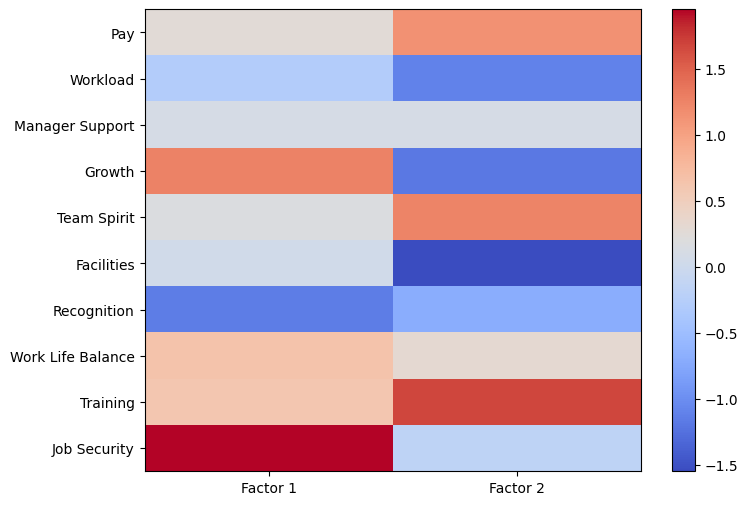


Factor Analysis with 3 Factors
                   Factor 1  Factor 2  Factor 3
Pay                1.161001  0.086430 -0.040888
Workload          -1.123289 -0.036584  0.154412
Manager Support    0.101069 -0.111021 -0.236710
Growth            -0.871244 -1.789682 -0.789398
Team Spirit        1.214040  0.159784 -0.356851
Facilities        -1.444547 -0.462963  0.392836
Recognition       -1.071321  0.820379 -0.599163
Work Life Balance  0.463461 -0.586606 -0.179162
Training           1.764028 -0.101802 -0.105347
Job Security       0.423287 -1.823893  0.297971


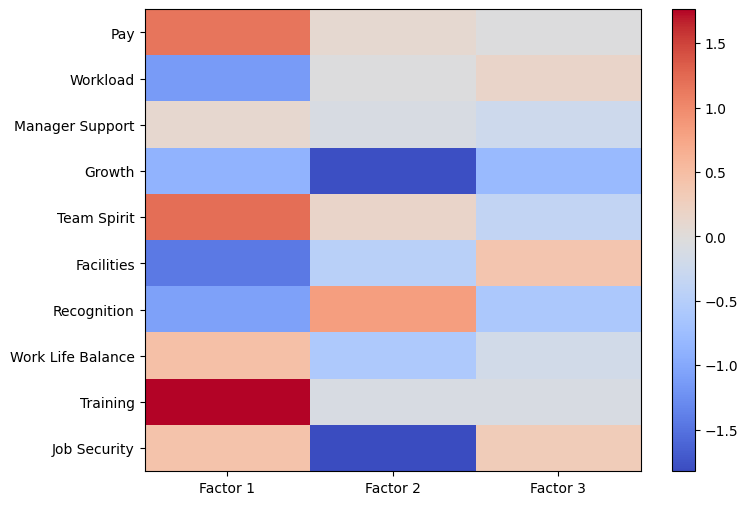


Factor Analysis with 4 Factors
                   Factor 1  Factor 2  Factor 3  Factor 4
Pay                1.162498  0.060298 -0.027725  0.021755
Workload          -1.125636 -0.011564  0.142430  0.079932
Manager Support    0.100836 -0.113061 -0.235331 -0.032941
Growth            -0.902708 -1.769475 -0.801580 -0.022691
Team Spirit        1.221006  0.132692 -0.343737  0.092010
Facilities        -1.462404 -0.432913  0.385481  0.136541
Recognition       -1.046296  0.844201 -0.608388  0.029117
Work Life Balance  0.452134 -0.597853 -0.175063  0.106337
Training           1.761977 -0.141469 -0.085143  0.062495
Job Security       0.379740 -1.833163  0.300592 -0.033997


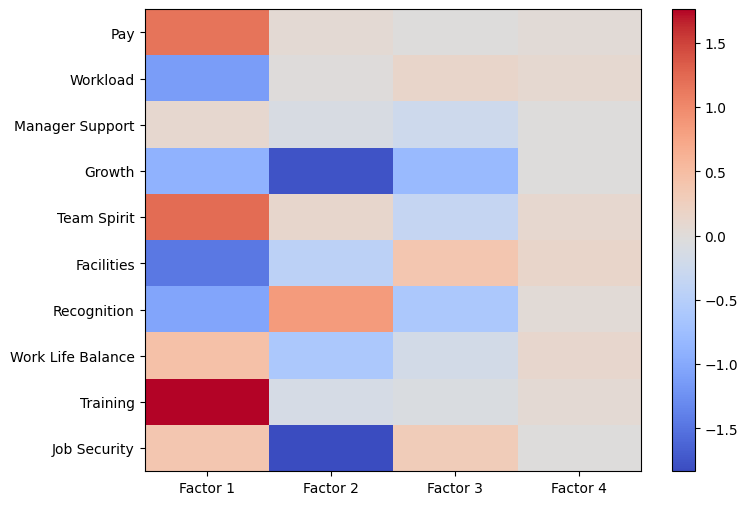

PCA Explained Variance: [0.50702401 0.34307799 0.07366025]
Varimax Factor Loadings:
                          0         1         2
Pay                1.039721  0.370531  0.372496
Workload          -1.060346 -0.259767 -0.308460
Manager Support    0.200632 -0.186599 -0.059158
Growth            -0.410257 -2.093603  0.183564
Team Spirit        1.238613  0.275813  0.128575
Facilities        -1.462188 -0.563249 -0.011352
Recognition       -0.642346  0.038914 -1.328768
Work Life Balance  0.484813 -0.435373  0.407933
Training           1.597366  0.353583  0.675766
Job Security       0.204549 -1.181978  1.468207


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis,PCA
np.random.seed(42)
n=300
factors=np.random.randn(n,3)
loadings=np.random.randn(3,10)
X=factors@loadings+np.random.randn(n,10)*0.5
columns=["Pay","Workload","Manager Support","Growth","Team Spirit","Facilities","Recognition","Work Life Balance","Training","Job Security"]
df=pd.DataFrame(X,columns=columns)
print(df.head())
print(df.corr())
for k in [2,3,4]:
    fa=FactorAnalysis(n_components=k,random_state=42)
    fa.fit(df)
    loading=pd.DataFrame(fa.components_.T,index=columns,columns=["Factor "+str(i+1) for i in range(k)])
    print("\nFactor Analysis with",k,"Factors")
    print(loading)
    plt.figure(figsize=(8,6))
    plt.imshow(loading,cmap="coolwarm",aspect="auto")
    plt.xticks(range(k),loading.columns)
    plt.yticks(range(10),columns)
    plt.colorbar()
    plt.show()
pca=PCA(n_components=3)
pca.fit(df)
print("PCA Explained Variance:",pca.explained_variance_ratio_)
fa=FactorAnalysis(n_components=3,rotation="varimax",random_state=42)
fa.fit(df)
print("Varimax Factor Loadings:")
print(pd.DataFrame(fa.components_.T,index=columns))

Experiment 22 – Independent Component Analysis and Component Visualization

ICA Correlation: 0.8326393971455381
PCA Correlation: 0.7601637349071284


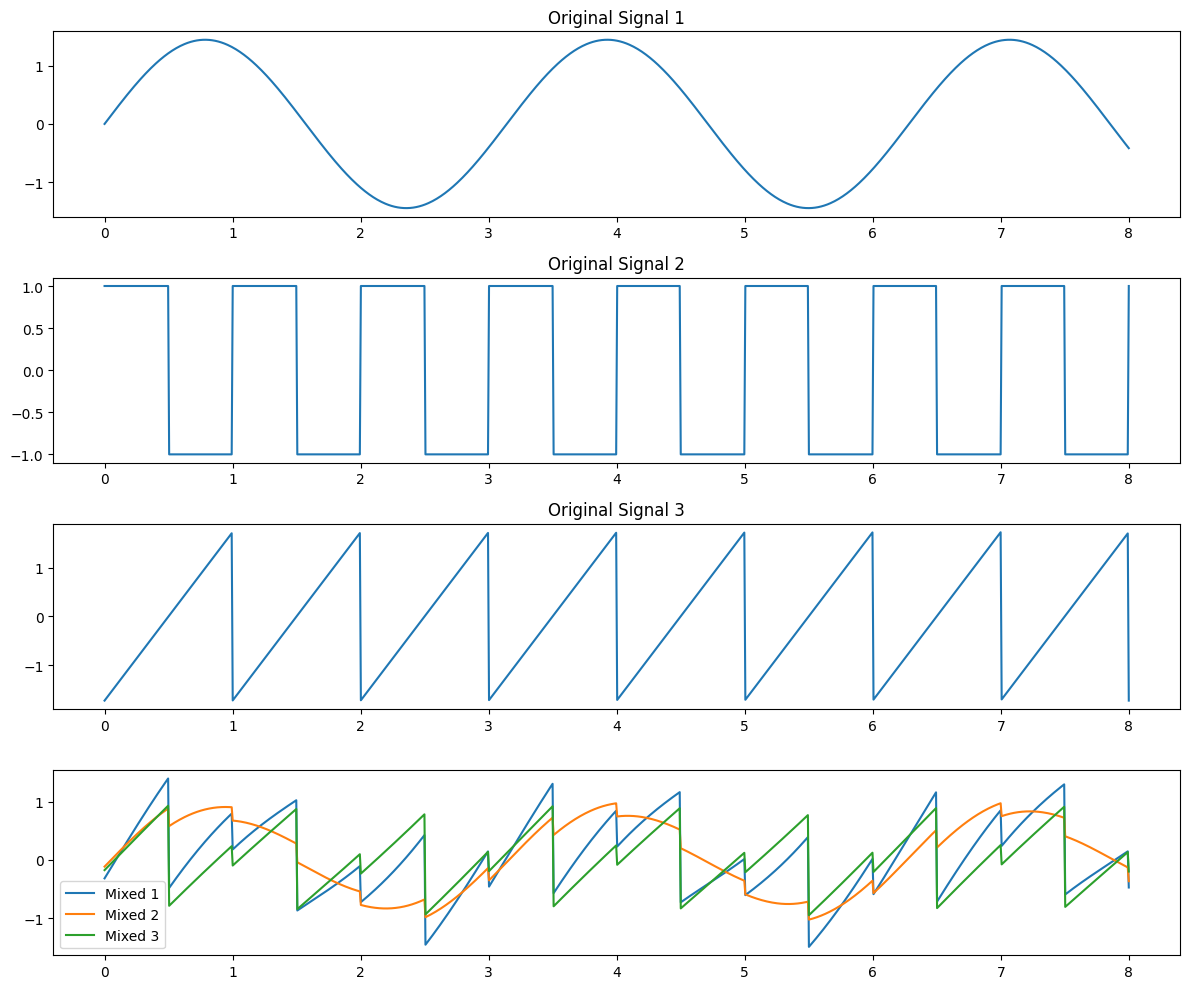

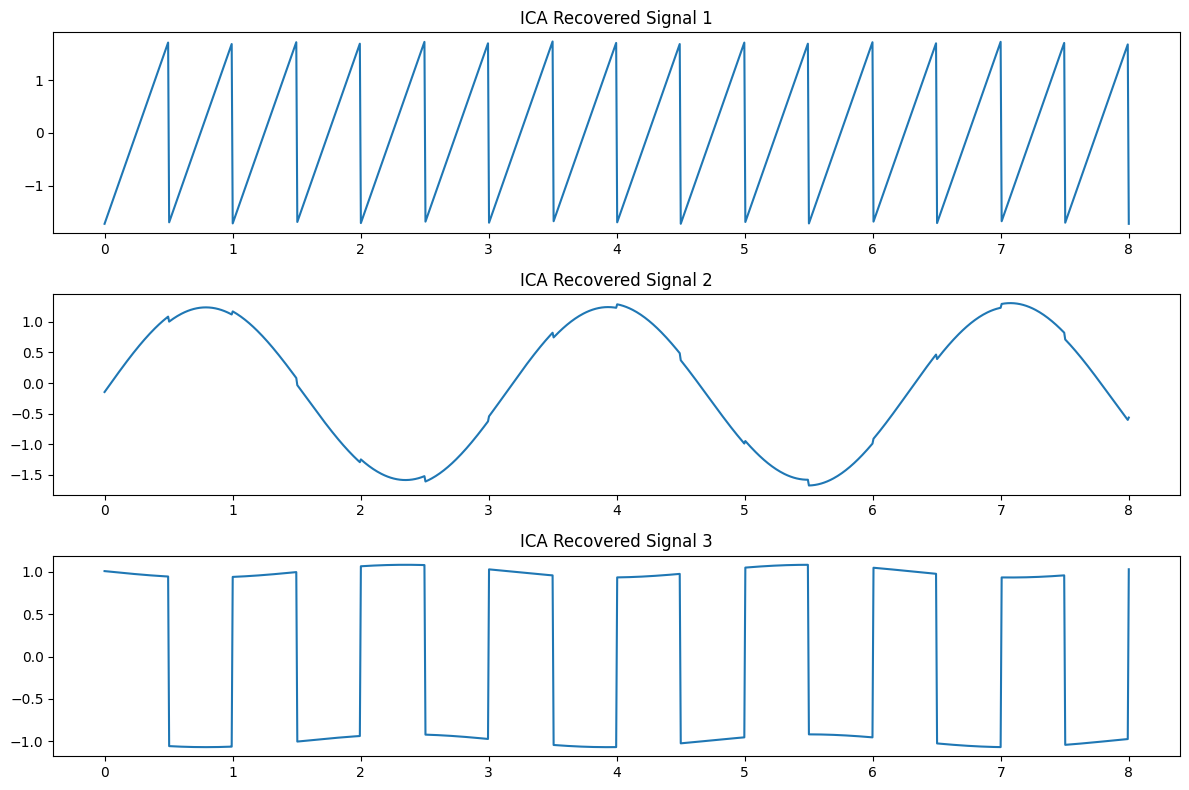

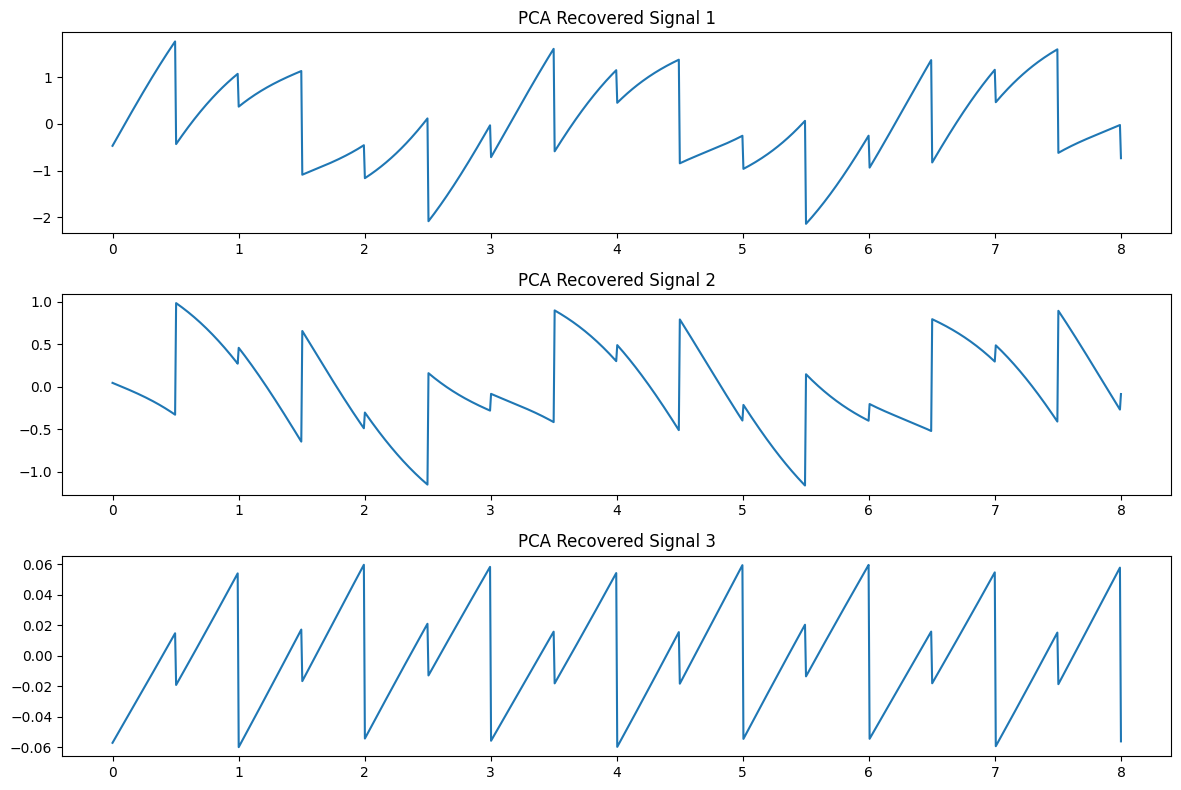

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import sawtooth,square
from sklearn.decomposition import FastICA,PCA
from scipy.optimize import linear_sum_assignment
np.random.seed(42)
t=np.linspace(0,8,1000)
S=np.c_[np.sin(2*t),square(2*np.pi*t),sawtooth(2*np.pi*t)]
S=S/np.std(S,axis=0)
A=np.random.rand(3,3)
X=S@A.T
ica=FastICA(n_components=3,random_state=42,max_iter=1000)
S_ica=ica.fit_transform(X)
S_pca=PCA(n_components=3).fit_transform(X)
def score(original,recovered):
    corr=np.abs(np.corrcoef(original.T,recovered.T)[:3,3:])
    rows,cols=linear_sum_assignment(-corr)
    return np.mean(corr[rows,cols])
print("ICA Correlation:",score(S,S_ica))
print("PCA Correlation:",score(S,S_pca))
plt.figure(figsize=(12,10))
for i in range(3):
    plt.subplot(4,1,i+1)
    plt.plot(t,S[:,i])
    plt.title("Original Signal "+str(i+1))
    plt.subplot(4,1,4)
    plt.plot(t,X[:,i],label="Mixed "+str(i+1))
plt.legend()
plt.tight_layout()
plt.show()
plt.figure(figsize=(12,8))
for i in range(3):
    plt.subplot(3,1,i+1)
    plt.plot(t,S_ica[:,i])
    plt.title("ICA Recovered Signal "+str(i+1))
plt.tight_layout()
plt.show()
plt.figure(figsize=(12,8))
for i in range(3):
    plt.subplot(3,1,i+1)
    plt.plot(t,S_pca[:,i])
    plt.title("PCA Recovered Signal "+str(i+1))
plt.tight_layout()
plt.show()

Experiment 23 – Bayesian Network Construction and Visualization

In [ ]:
!pip install -q pgmpy

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Model Valid: True


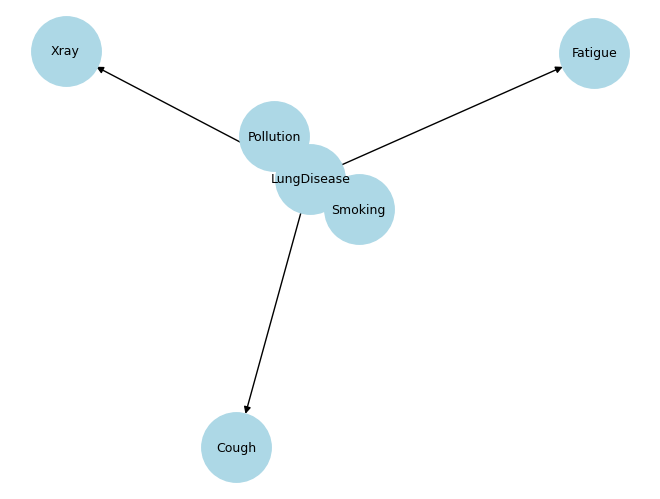

Conditional independencies:
(Pollution ⟂ Xray | LungDisease)
(Cough ⟂ Fatigue | LungDisease)
(Cough ⟂ Pollution | LungDisease)
(Cough ⟂ Smoking | LungDisease)
(Fatigue ⟂ Smoking | LungDisease)
(Smoking ⟂ Xray | LungDisease)
(Cough ⟂ Xray | LungDisease)
(Pollution ⟂ Smoking)
(Fatigue ⟂ Pollution | LungDisease)
(Fatigue ⟂ Xray | LungDisease)
Active Trails:
Smoking {'Smoking': {'Cough', 'LungDisease', 'Smoking', 'Xray', 'Fatigue'}}
LungDisease {'LungDisease': {'Xray', 'Cough', 'LungDisease', 'Smoking', 'Pollution', 'Fatigue'}}
Pollution {'Pollution': {'Xray', 'Cough', 'LungDisease', 'Pollution', 'Fatigue'}}
Cough {'Cough': {'Pollution', 'Cough', 'LungDisease', 'Smoking', 'Xray', 'Fatigue'}}
Xray {'Xray': {'Pollution', 'Cough', 'LungDisease', 'Smoking', 'Xray', 'Fatigue'}}
Fatigue {'Fatigue': {'Xray', 'Cough', 'LungDisease', 'Smoking', 'Pollution', 'Fatigue'}}


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
model=DiscreteBayesianNetwork([("Smoking","LungDisease"),("Pollution","LungDisease"),("LungDisease","Cough"),("LungDisease","Xray"),("LungDisease","Fatigue")])
cpd_smoking=TabularCPD("Smoking",2,[[0.7],[0.3]])
cpd_pollution=TabularCPD("Pollution",2,[[0.6],[0.4]])
cpd_lung=TabularCPD("LungDisease",2,[[0.99,0.9,0.8,0.1],[0.01,0.1,0.2,0.9]],evidence=["Smoking","Pollution"],evidence_card=[2,2])
cpd_cough=TabularCPD("Cough",2,[[0.8,0.2],[0.2,0.8]],evidence=["LungDisease"],evidence_card=[2])
cpd_xray=TabularCPD("Xray",2,[[0.9,0.1],[0.1,0.9]],evidence=["LungDisease"],evidence_card=[2])
cpd_fatigue=TabularCPD("Fatigue",2,[[0.7,0.3],[0.3,0.7]],evidence=["LungDisease"],evidence_card=[2])
model.add_cpds(cpd_smoking,cpd_pollution,cpd_lung,cpd_cough,cpd_xray,cpd_fatigue)
print("Model Valid:",model.check_model())
G=nx.DiGraph(model.edges())
pos=nx.spring_layout(G,seed=42)
nx.draw(G,pos,with_labels=True,node_color="lightblue",node_size=2500,arrows=True,font_size=9)
plt.show()
inference=VariableElimination(model)
print("Conditional independencies:")
print(model.get_independencies())
print("Active Trails:")
for node in model.nodes():
    print(node,model.active_trail_nodes(node))

Experiment 24 – Graphical Model Sampling and Probabilistic Inference

In [ ]:
!pip install -q pgmpy

In [ ]:
import pgmpy
print(pgmpy.__version__)

1.1.2


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling

In [ ]:
%pip install --upgrade --no-cache-dir pgmpy

Evidence: {'Xray': 1, 'Cough': 1}
+----------------+--------------------+
| LungDisease    |   phi(LungDisease) |
+================+====================+
| LungDisease(0) |             0.1149 |
+----------------+--------------------+
| LungDisease(1) |             0.8851 |
+----------------+--------------------+
Evidence: {'Xray': 1, 'Cough': 1, 'Smoking': 1}
+----------------+--------------------+
| LungDisease    |   phi(LungDisease) |
+================+====================+
| LungDisease(0) |             0.0292 |
+----------------+--------------------+
| LungDisease(1) |             0.9708 |
+----------------+--------------------+
Evidence: {'Xray': 1, 'Cough': 1, 'Smoking': 0}
+----------------+--------------------+
| LungDisease    |   phi(LungDisease) |
+================+====================+
| LungDisease(0) |             0.3655 |
+----------------+--------------------+
| LungDisease(1) |             0.6345 |
+----------------+--------------------+
Forward Sampling:
   Smoking  

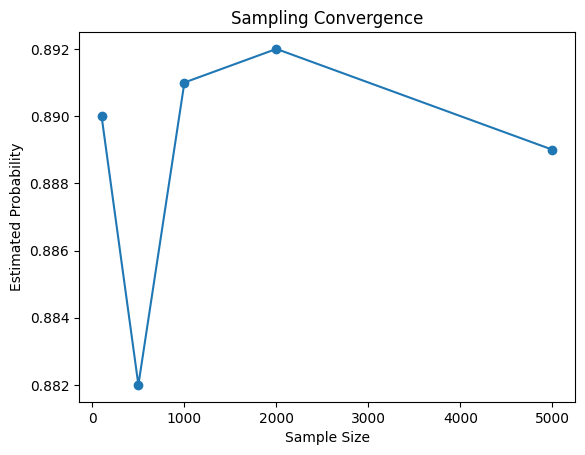

               Method  Probability
0               Exact     0.885057
1  Rejection Sampling     0.889000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling
model=DiscreteBayesianNetwork([("Smoking","LungDisease"),("Pollution","LungDisease"),("LungDisease","Cough"),("LungDisease","Xray"),("LungDisease","Fatigue")])
cpds=[TabularCPD("Smoking",2,[[0.7],[0.3]]),TabularCPD("Pollution",2,[[0.6],[0.4]]),TabularCPD("LungDisease",2,[[0.99,0.9,0.8,0.1],[0.01,0.1,0.2,0.9]],evidence=["Smoking","Pollution"],evidence_card=[2,2]),TabularCPD("Cough",2,[[0.8,0.2],[0.2,0.8]],evidence=["LungDisease"],evidence_card=[2]),TabularCPD("Xray",2,[[0.9,0.1],[0.1,0.9]],evidence=["LungDisease"],evidence_card=[2]),TabularCPD("Fatigue",2,[[0.7,0.3],[0.3,0.7]],evidence=["LungDisease"],evidence_card=[2])]
model.add_cpds(*cpds)
inference=VariableElimination(model)
sampler=BayesianModelSampling(model)
evidences=[{"Xray":1,"Cough":1},{"Xray":1,"Cough":1,"Smoking":1},{"Xray":1,"Cough":1,"Smoking":0}]
for evidence in evidences:
    result=inference.query(["LungDisease"],evidence=evidence)
    print("Evidence:",evidence)
    print(result)
samples=sampler.forward_sample(size=10000,show_progress=False)
rejection=sampler.rejection_sample(evidence=[("Xray",1),("Cough",1)],size=5000,show_progress=False)
print("Forward Sampling:")
print(samples.head())
print("Rejection Sampling:")
print(rejection.head())
sizes=[100,500,1000,2000,5000]
estimates=[]
for size in sizes:
    subset=rejection.iloc[:size]
    estimates.append(np.mean(subset["LungDisease"]==1))
plt.plot(sizes,estimates,marker="o")
plt.xlabel("Sample Size")
plt.ylabel("Estimated Probability")
plt.title("Sampling Convergence")
plt.show()
exact=inference.query(["LungDisease"],evidence={"Xray":1,"Cough":1}).values[1]
approx=np.mean(rejection["LungDisease"]==1)
print(pd.DataFrame({"Method":["Exact","Rejection Sampling"],"Probability":[exact,approx]}))

Experiment 25 – Restricted Boltzmann Machine Energy and Reconstruction

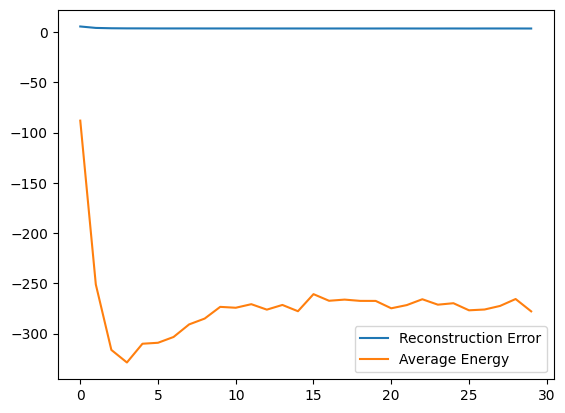

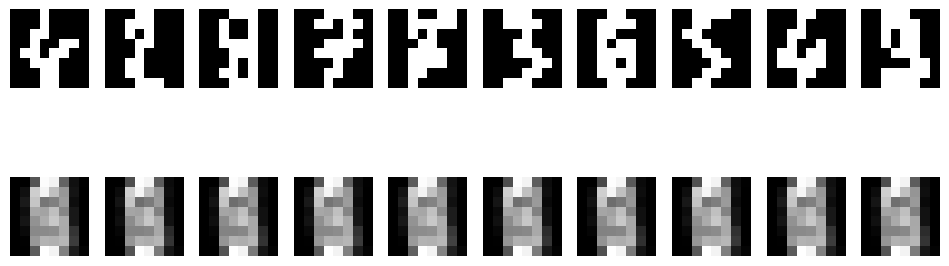

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import MinMaxScaler
np.random.seed(42)
X=load_digits().data
X=(X>8).astype(float)
nv=64
nh=32
W=np.random.normal(0,0.01,(nv,nh))
a=np.zeros(nv)
b=np.zeros(nh)
def sigmoid(x):
    return 1/(1+np.exp(-np.clip(x,-50,50)))
def hidden(v):
    return sigmoid(v@W+b)
def visible(h):
    return sigmoid(h@W.T+a)
def energy(v,h):
    return -np.sum(v*a,axis=1)-np.sum(h*b,axis=1)-np.sum((v@W)*h,axis=1)
errors=[]
free_energy=[]
lr=0.01
batch_size=64
for epoch in range(30):
    np.random.shuffle(X)
    total_error=0
    total_energy=0
    for i in range(0,len(X),batch_size):
        v0=X[i:i+batch_size]
        ph0=hidden(v0)
        h0=(np.random.rand(*ph0.shape)<ph0).astype(float)
        pv1=visible(h0)
        v1=(np.random.rand(*pv1.shape)<pv1).astype(float)
        ph1=hidden(v1)
        W+=lr*((v0.T@ph0-v1.T@ph1)/len(v0))
        a+=lr*np.mean(v0-v1,axis=0)
        b+=lr*np.mean(ph0-ph1,axis=0)
        total_error+=np.mean((v0-pv1)**2)
        total_energy+=np.mean(energy(v0,h0))
    errors.append(total_error)
    free_energy.append(total_energy)
plt.plot(errors,label="Reconstruction Error")
plt.plot(free_energy,label="Average Energy")
plt.legend()
plt.show()
samples=X[:10]
reconstructed=visible(hidden(samples))
plt.figure(figsize=(12,4))
for i in range(10):
    plt.subplot(2,10,i+1)
    plt.imshow(samples[i].reshape(8,8),cmap="gray")
    plt.axis("off")
    plt.subplot(2,10,i+11)
    plt.imshow(reconstructed[i].reshape(8,8),cmap="gray")
    plt.axis("off")
plt.show()

Experiment 26 – Gibbs Sampling and Contrastive Divergence Analysis

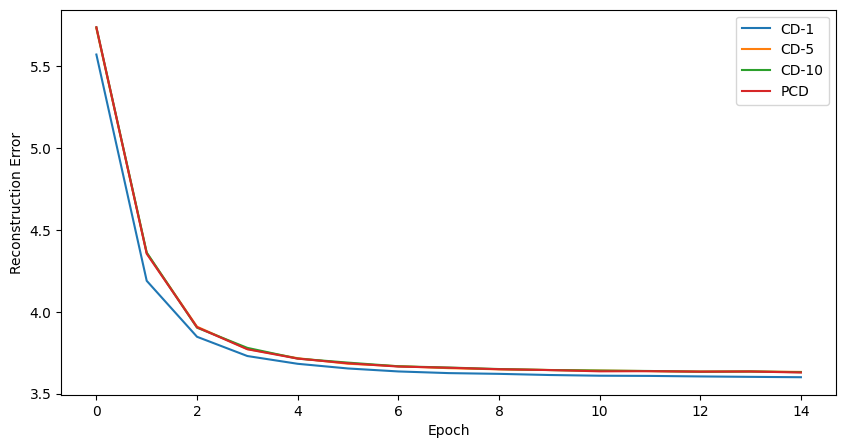

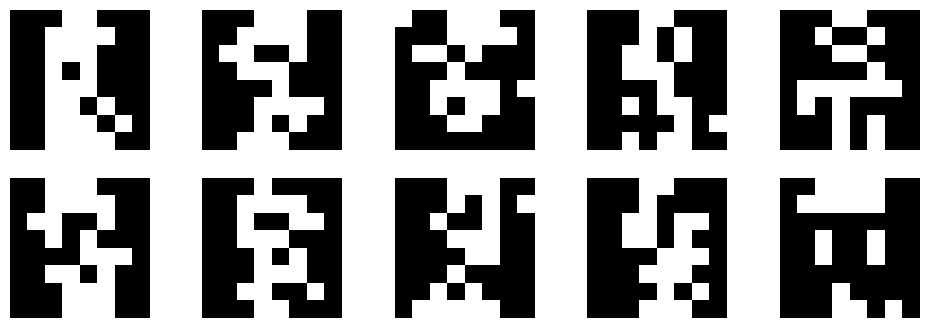

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
np.random.seed(42)
X=(load_digits().data>8).astype(float)
nv=64
nh=32
def sigmoid(x):
    return 1/(1+np.exp(-np.clip(x,-50,50)))
def train_rbm(X,method,epochs=15):
    W=np.random.normal(0,0.01,(nv,nh))
    a=np.zeros(nv)
    b=np.zeros(nh)
    errors=[]
    persistent=np.random.binomial(1,0.5,(64,nv)).astype(float)
    for epoch in range(epochs):
        total=0
        np.random.shuffle(X)
        for i in range(0,len(X)-64,64):
            v0=X[i:i+64]
            ph0=sigmoid(v0@W+b)
            if method=="PCD":
                vk=persistent
            else:
                vk=v0.copy()
            steps=1 if method=="CD-1" else 5 if method=="CD-5" else 10 if method=="CD-10" else 5
            for j in range(steps):
                hk=(np.random.rand(64,nh)<sigmoid(vk@W+b)).astype(float)
                pv=sigmoid(hk@W.T+a)
                vk=(np.random.rand(64,nv)<pv).astype(float)
            if method=="PCD":
                persistent=vk
            phk=sigmoid(vk@W+b)
            W+=0.01*((v0.T@ph0-vk.T@phk)/64)
            a+=0.01*np.mean(v0-vk,axis=0)
            b+=0.01*np.mean(ph0-phk,axis=0)
            total+=np.mean((v0-pv)**2)
        errors.append(total)
    return W,a,b,errors
results={}
for method in ["CD-1","CD-5","CD-10","PCD"]:
    results[method]=train_rbm(X,method)
plt.figure(figsize=(10,5))
for method,result in results.items():
    plt.plot(result[3],label=method)
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()
W,a,b,_=results["CD-5"]
v=np.random.binomial(1,0.5,(10,nv)).astype(float)
plt.figure(figsize=(12,4))
for i in range(10):
    h=(np.random.rand(nh)<sigmoid(v[i]@W+b)).astype(float)
    for j in range(100):
        pv=sigmoid(h@W.T+a)
        v[i]=(np.random.rand(nv)<pv).astype(float)
        h=(np.random.rand(nh)<sigmoid(v[i]@W+b)).astype(float)
    plt.subplot(2,5,i+1)
    plt.imshow(v[i].reshape(8,8),cmap="gray")
    plt.axis("off")
plt.show()

Experiment 27 – Deep Belief Network Representation Learning

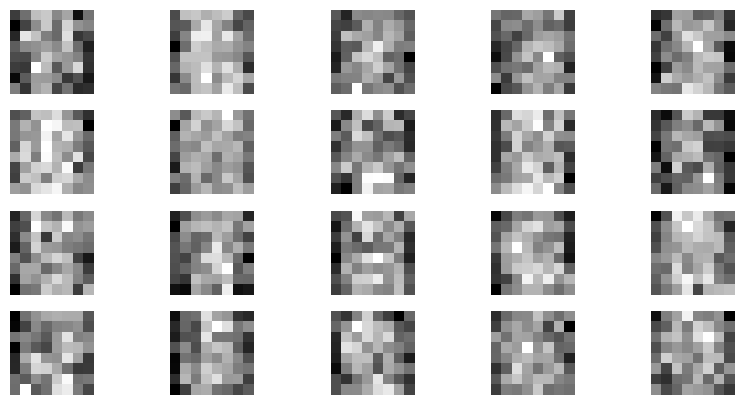

Pretrained Accuracy: 0.9166666865348816
Random Accuracy: 0.9305555820465088


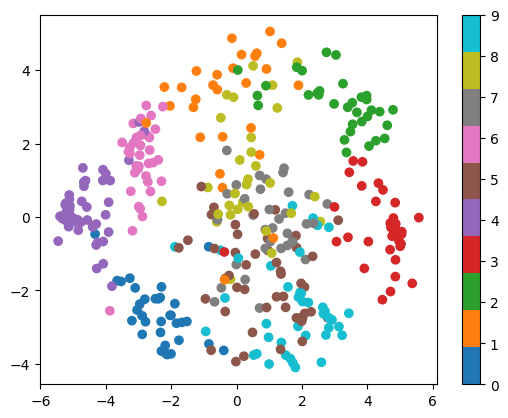

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
np.random.seed(42)
digits=load_digits()
X=digits.data/16.0
y=digits.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
def sigmoid(x):
    return 1/(1+np.exp(-np.clip(x,-50,50)))
def train_rbm(data,n_hidden,epochs=10):
    W=np.random.normal(0,0.01,(data.shape[1],n_hidden))
    a=np.zeros(data.shape[1])
    b=np.zeros(n_hidden)
    for epoch in range(epochs):
        for i in range(0,len(data)-64,64):
            v0=data[i:i+64]
            ph0=sigmoid(v0@W+b)
            h0=(np.random.rand(*ph0.shape)<ph0).astype(float)
            pv1=sigmoid(h0@W.T+a)
            v1=(np.random.rand(*pv1.shape)<pv1).astype(float)
            ph1=sigmoid(v1@W+b)
            W+=0.01*((v0.T@ph0-v1.T@ph1)/len(v0))
            a+=0.01*np.mean(v0-v1,axis=0)
            b+=0.01*np.mean(ph0-ph1,axis=0)
    return W,a,b
W1,a1,b1=train_rbm(X_train,500)
H1=sigmoid(X_train@W1+b1)
W2,a2,b2=train_rbm(H1,250)
H2=sigmoid(H1@W2+b2)
plt.figure(figsize=(10,5))
for i in range(20):
    plt.subplot(4,5,i+1)
    plt.imshow(W1[:,i].reshape(8,8),cmap="gray")
    plt.axis("off")
plt.show()
def create_model(pretrained):
    model=tf.keras.Sequential([tf.keras.layers.Input(shape=(64,)),tf.keras.layers.Dense(500,activation="sigmoid"),tf.keras.layers.Dense(250,activation="sigmoid"),tf.keras.layers.Dense(10,activation="softmax")])
    if pretrained:
        model.layers[0].set_weights([W1,b1])
        model.layers[1].set_weights([W2,b2])
    model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model
pretrained=create_model(True)
random_model=create_model(False)
pretrained.fit(X_train[:1000],y_train[:1000],epochs=20,batch_size=32,verbose=0)
random_model.fit(X_train[:1000],y_train[:1000],epochs=20,batch_size=32,verbose=0)
print("Pretrained Accuracy:",pretrained.evaluate(X_test,y_test,verbose=0)[1])
print("Random Accuracy:",random_model.evaluate(X_test,y_test,verbose=0)[1])
features=pretrained.layers[1](pretrained.layers[0](X_test)).numpy()
reduced=PCA(n_components=2).fit_transform(features)
plt.scatter(reduced[:,0],reduced[:,1],c=y_test,cmap="tab10")
plt.colorbar()
plt.show()

Experiment 28 – Deep Boltzmann Machine / Convolutional Boltzmann Machine Simulation

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden (MaxPooling2D)           │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 32)     │         9,248 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 16)     │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,817 (73.50 KB)

 Trainable params: 18,817 (73.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 16s 335ms/step - loss: 0.4381 - val_loss: 0.4198
Epoch 2/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 10s 289ms/step - loss: 0.3975 - val_loss: 0.4096
Epoch 3/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 154ms/step - loss: 0.3908 - val_loss: 0.4023
Epoch 4/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 139ms/step - loss: 0.3821 - val_loss: 0.3900
Epoch 5/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 189ms/step - loss: 0.3621 - val_loss: 0.3554


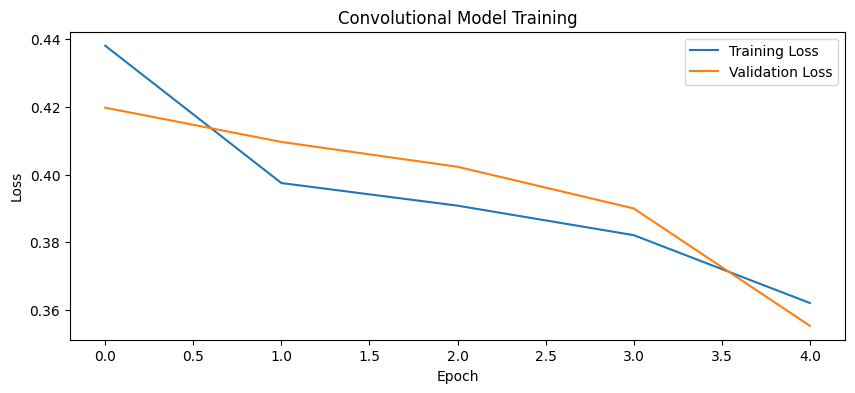

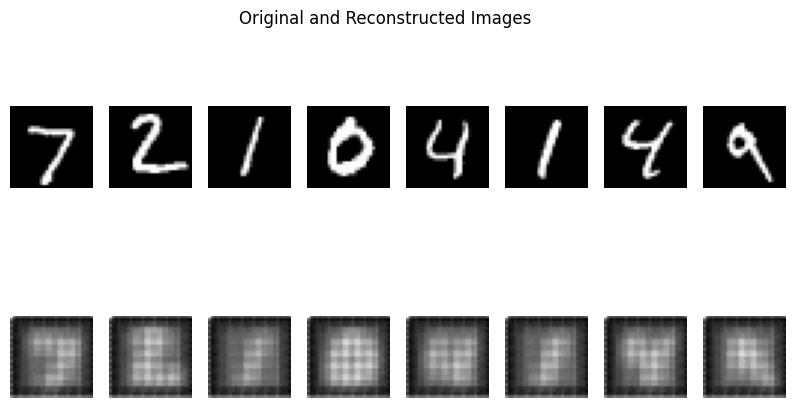

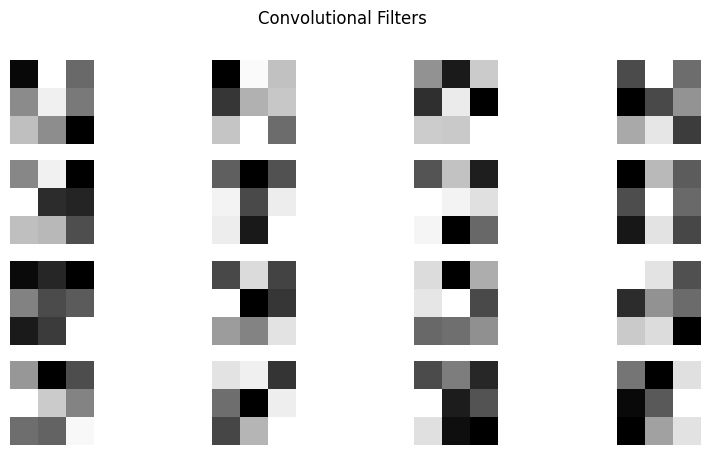

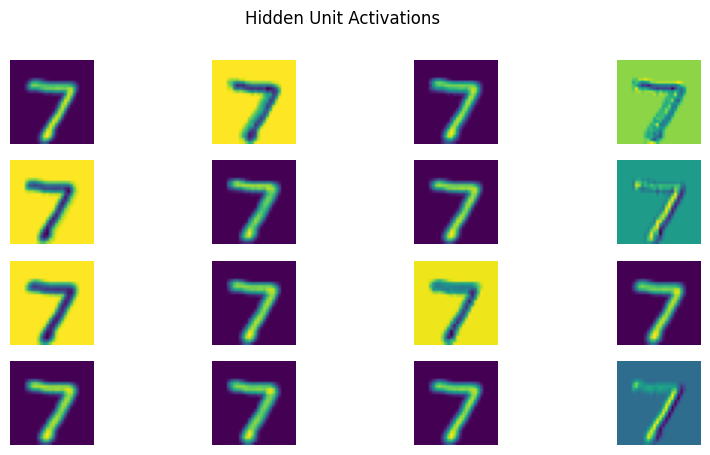

Convolutional Model Reconstruction Error: 0.0787973552942276
Single Layer RBM Reconstruction Error: 0.13510680198669434


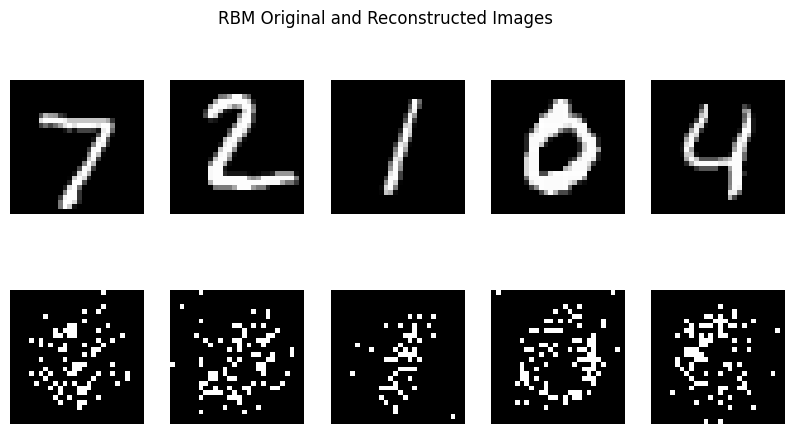

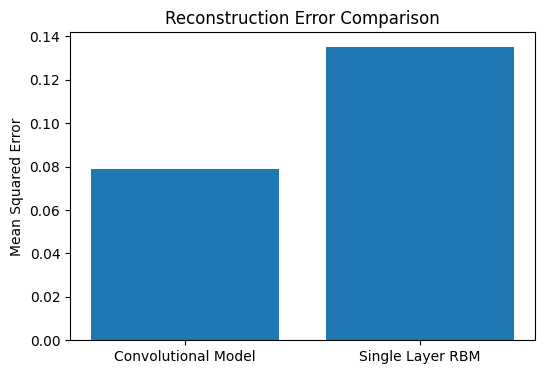

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import BernoulliRBM
from sklearn.metrics import mean_squared_error

np.random.seed(42)
tf.random.set_seed(42)

(x_train,_),(x_test,_)=tf.keras.datasets.mnist.load_data()
x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0
x_train=x_train[:5000]
x_test=x_test[:500]
X=x_train[...,np.newaxis]
X_test=x_test[...,np.newaxis]

inputs=tf.keras.Input(shape=(28,28,1))
x=tf.keras.layers.Conv2D(16,(3,3),activation="sigmoid",padding="same",name="conv1")(inputs)
x=tf.keras.layers.MaxPooling2D((2,2),padding="same")(x)
x=tf.keras.layers.Conv2D(32,(3,3),activation="sigmoid",padding="same",name="conv2")(x)
encoded=tf.keras.layers.MaxPooling2D((2,2),padding="same",name="hidden")(x)
x=tf.keras.layers.Conv2DTranspose(32,(3,3),strides=2,activation="sigmoid",padding="same")(encoded)
x=tf.keras.layers.Conv2DTranspose(16,(3,3),strides=2,activation="sigmoid",padding="same")(x)
decoded=tf.keras.layers.Conv2D(1,(3,3),activation="sigmoid",padding="same")(x)

model=tf.keras.Model(inputs,decoded)
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),loss="binary_crossentropy")
model.summary()

history=model.fit(X,X,epochs=5,batch_size=128,validation_split=0.1,verbose=1)

reconstructed=model.predict(X_test,verbose=0)

plt.figure(figsize=(10,4))
plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Convolutional Model Training")
plt.legend()
plt.show()

plt.figure(figsize=(10,5))
for i in range(8):
    plt.subplot(2,8,i+1)
    plt.imshow(X_test[i].squeeze(),cmap="gray")
    plt.axis("off")
    plt.subplot(2,8,i+9)
    plt.imshow(reconstructed[i].squeeze(),cmap="gray")
    plt.axis("off")
plt.suptitle("Original and Reconstructed Images")
plt.show()

filters=model.get_layer("conv1").get_weights()[0]
plt.figure(figsize=(10,5))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(filters[:,:,0,i],cmap="gray")
    plt.axis("off")
plt.suptitle("Convolutional Filters")
plt.show()

activation_model=tf.keras.Model(inputs=model.inputs,outputs=model.get_layer("conv1").output)
activations=activation_model.predict(X_test[:1],verbose=0)

plt.figure(figsize=(10,5))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(activations[0,:,:,i],cmap="viridis")
    plt.axis("off")
plt.suptitle("Hidden Unit Activations")
plt.show()

rbm=BernoulliRBM(n_components=64,learning_rate=0.01,batch_size=64,n_iter=10,random_state=42,verbose=False)
rbm.fit(x_train.reshape(len(x_train),-1))
rbm_reconstructed=rbm.gibbs(x_test.reshape(len(x_test),-1))
rbm_reconstructed=np.clip(rbm_reconstructed.reshape(-1,28,28),0,1)

conv_error=mean_squared_error(X_test.reshape(-1),reconstructed.reshape(-1))
rbm_error=mean_squared_error(x_test.reshape(-1),rbm_reconstructed.reshape(-1))

print("Convolutional Model Reconstruction Error:",conv_error)
print("Single Layer RBM Reconstruction Error:",rbm_error)

plt.figure(figsize=(10,5))
for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(x_test[i],cmap="gray")
    plt.axis("off")
    plt.subplot(2,5,i+6)
    plt.imshow(rbm_reconstructed[i],cmap="gray")
    plt.axis("off")
plt.suptitle("RBM Original and Reconstructed Images")
plt.show()

plt.figure(figsize=(6,4))
plt.bar(["Convolutional Model","Single Layer RBM"],[conv_error,rbm_error])
plt.ylabel("Mean Squared Error")
plt.title("Reconstruction Error Comparison")
plt.show()


Experiment 29 – VAE/GAN Sample Generation

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - kl_loss: 15.6970 - loss: 261.4435 - reconstruction_loss: 245.7465
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 15.6936 - loss: 261.2869 - reconstruction_loss: 245.5932
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - kl_loss: 16.4881 - loss: 242.5771 - reconstruction_loss: 226.0890
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 16.2900 - loss: 252.1582 - reconstruction_loss: 235.8682
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 15.3507 - loss: 240.1226 - reconstruction_loss: 224.7720
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 15.9043 - loss: 237.4310 - reconstruction_loss: 221.5267
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 17.1338 - loss: 260.0765 - r

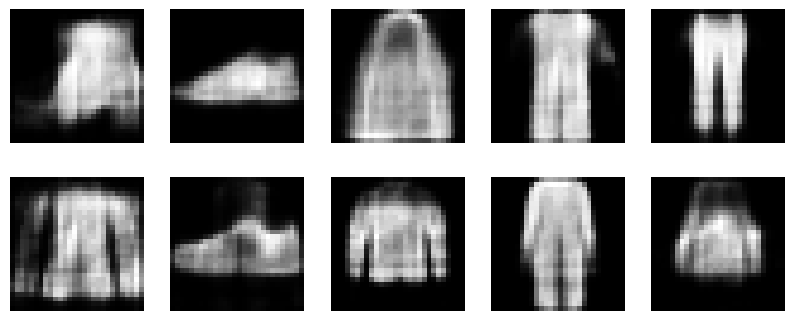

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
(x_train,_),(x_test,_)=tf.keras.datasets.fashion_mnist.load_data()
x_train=x_train.astype("float32")/255.0
x_train=x_train.reshape(-1,28,28,1)
latent_dim=16
encoder_input=tf.keras.Input(shape=(28,28,1))
x=tf.keras.layers.Flatten()(encoder_input)
x=tf.keras.layers.Dense(256,activation="relu")(x)
z_mean=tf.keras.layers.Dense(latent_dim)(x)
z_log_var=tf.keras.layers.Dense(latent_dim)(x)
def sampling(args):
    mean,log_var=args
    epsilon=tf.random.normal(shape=tf.shape(mean))
    return mean+tf.exp(0.5*log_var)*epsilon
z=tf.keras.layers.Lambda(sampling)([z_mean,z_log_var])
encoder=tf.keras.Model(encoder_input,[z_mean,z_log_var,z])
decoder_input=tf.keras.Input(shape=(latent_dim,))
x=tf.keras.layers.Dense(256,activation="relu")(decoder_input)
x=tf.keras.layers.Dense(784,activation="sigmoid")(x)
decoder_output=tf.keras.layers.Reshape((28,28,1))(x)
decoder=tf.keras.Model(decoder_input,decoder_output)
class VAE(tf.keras.Model):
    def __init__(self,encoder,decoder):
        super().__init__()
        self.encoder=encoder
        self.decoder=decoder
    def train_step(self,data):
        with tf.GradientTape() as tape:
            mean,log_var,z=self.encoder(data)
            reconstruction=self.decoder(z)
            rec=tf.reduce_mean(tf.reduce_sum(tf.keras.losses.binary_crossentropy(data,reconstruction),axis=(1,2)))
            kl=-0.5*tf.reduce_mean(tf.reduce_sum(1+log_var-tf.square(mean)-tf.exp(log_var),axis=1))
            loss=rec+kl
        gradients=tape.gradient(loss,self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients,self.trainable_variables))
        return {"loss":loss,"reconstruction_loss":rec,"kl_loss":kl}
vae=VAE(encoder,decoder)
vae.compile(optimizer="adam")
vae.fit(x_train,epochs=10,batch_size=128)
z_samples=np.random.normal(size=(10,latent_dim))
generated=decoder.predict(z_samples)
plt.figure(figsize=(10,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(generated[i,:,:,0],cmap="gray")
    plt.axis("off")
plt.show()
generator=tf.keras.Sequential([tf.keras.layers.Input(shape=(100,)),tf.keras.layers.Dense(7*7*128),tf.keras.layers.Reshape((7,7,128)),tf.keras.layers.BatchNormalization(),tf.keras.layers.Conv2DTranspose(128,4,strides=2,padding="same",activation="relu"),tf.keras.layers.BatchNormalization(),tf.keras.layers.Conv2DTranspose(64,4,strides=2,padding="same",activation="relu"),tf.keras.layers.Conv2D(1,3,padding="same",activation="sigmoid")])
discriminator=tf.keras.Sequential([tf.keras.layers.Input(shape=(28,28,1)),tf.keras.layers.Conv2D(64,4,strides=2,padding="same"),tf.keras.layers.LeakyReLU(0.2),tf.keras.layers.Dropout(0.3),tf.keras.layers.Conv2D(128,4,strides=2,padding="same"),tf.keras.layers.LeakyReLU(0.2),tf.keras.layers.Flatten(),tf.keras.layers.Dense(1)])
g_optimizer=tf.keras.optimizers.Adam(0.0002)
d_optimizer=tf.keras.optimizers.Adam(0.0002)
loss_fn=tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_losses=[]
d_losses=[]
for epoch in range(10):
    for i in range(0,len(x_train),128):
        real=x_train[i:i+128]
        bs=len(real)
        noise=tf.random.normal((bs,100))
        with tf.GradientTape() as gt,tf.GradientTape() as dt:
            fake=generator(noise,training=True)
            real_output=discriminator(real,training=True)
            fake_output=discriminator(fake,training=True)
            g_loss=loss_fn(tf.ones_like(fake_output),fake_output)
            d_loss=loss_fn(tf.ones_like(real_output),real_output)+loss_fn(tf.zeros_like(fake_output),fake_output)
        gg=gt.gradient(g_loss,generator.trainable_variables)
        dg=dt.gradient(d_loss,discriminator.trainable_variables)
        g_optimizer.apply_gradients(zip(gg,generator.trainable_variables))
        d_optimizer.apply_gradients(zip(dg,discriminator.trainable_variables))
    g_losses.append(float(g_loss))
    d_losses.append(float(d_loss))
    generated=generator(tf.random.normal((10,100))).numpy()
    plt.figure(figsize=(8,3))
    for j in range(10):
        plt.subplot(2,5,j+1)
        plt.imshow(generated[j,:,:,0],cmap="gray")
        plt.axis("off")
    plt.savefig("generated_epoch_"+str(epoch+1)+".png")
    plt.close()
plt.plot(g_losses,label="Generator")
plt.plot(d_losses,label="Discriminator")
plt.legend()
plt.show()

Experiment 30 – Generative Model Output Comparison and Evaluation

Epoch 1/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.7910 - loss: 0.5983 - val_accuracy: 0.8353 - val_loss: 0.4670
Epoch 2/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8517 - loss: 0.4127 - val_accuracy: 0.8597 - val_loss: 0.4055
Epoch 3/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8664 - loss: 0.3656 - val_accuracy: 0.8653 - val_loss: 0.3816
Classifier Test Accuracy: 0.8579999804496765
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 54s 219ms/step - loss: 334.0042
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 53s 226ms/step - loss: 265.7208
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 219ms/step - loss: 256.0777
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 82s 218ms/step - loss: 251.3815
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 218ms/step - loss: 248.7536
GAN Epoch 1 Generator Loss: 0.9678 Discriminator Loss: 0.7911
GAN Epoch 2 Generator Loss: 1.0733 Discriminator Loss: 1.1231
GAN Epoch 3 Generator Loss: 1.7666 Discriminator Loss: 0.7835
GAN Epoch 4 Generator Loss: 1.1

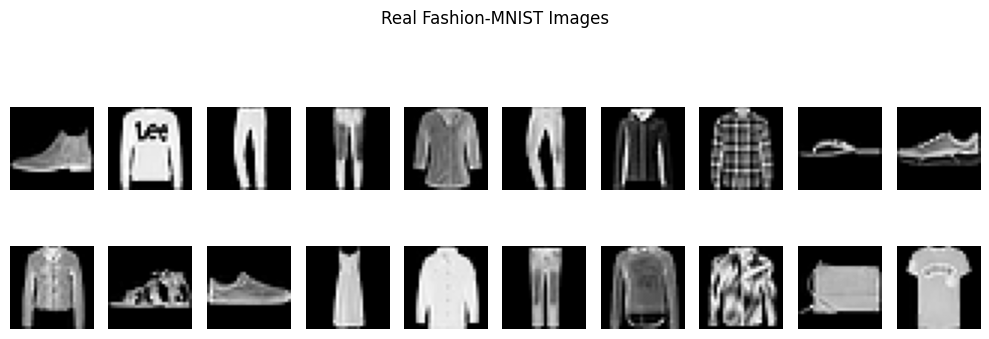

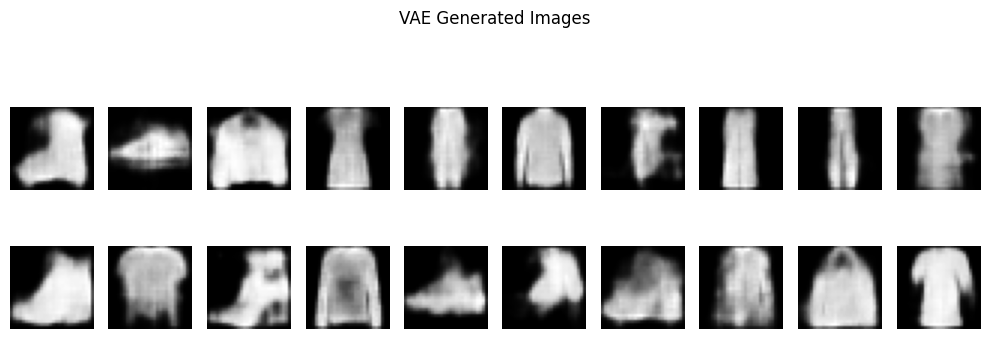

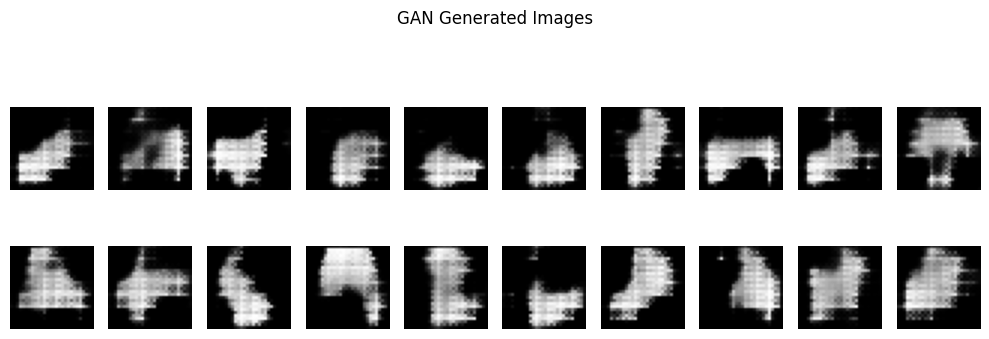

/tmp/ipykernel_610/537695277.py:195: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covariance_mean=sqrtm(sigma1@sigma2)



GENERATIVE MODEL COMPARISON
           Metric   Real     VAE     GAN
  Inception Score    NaN  4.1881  3.7752
              FID 0.0000 20.0556 47.4762
Feature Diversity 1.1033  0.5886  0.5418

CLASS DISTRIBUTION
Fashion Class  Real (%)  VAE (%)  GAN (%)
  T-shirt/top      10.6      7.4      4.8
      Trouser      10.4      9.2      9.6
     Pullover      11.1      6.7      1.0
        Dress       8.7     10.9     10.2
         Coat      12.0     16.9     14.2
       Sandal       8.2      5.7      7.8
        Shirt      10.1      8.9      6.1
      Sneaker      10.1     11.4      9.9
          Bag       9.4     13.0     26.5
   Ankle boot       9.4      9.9      9.9


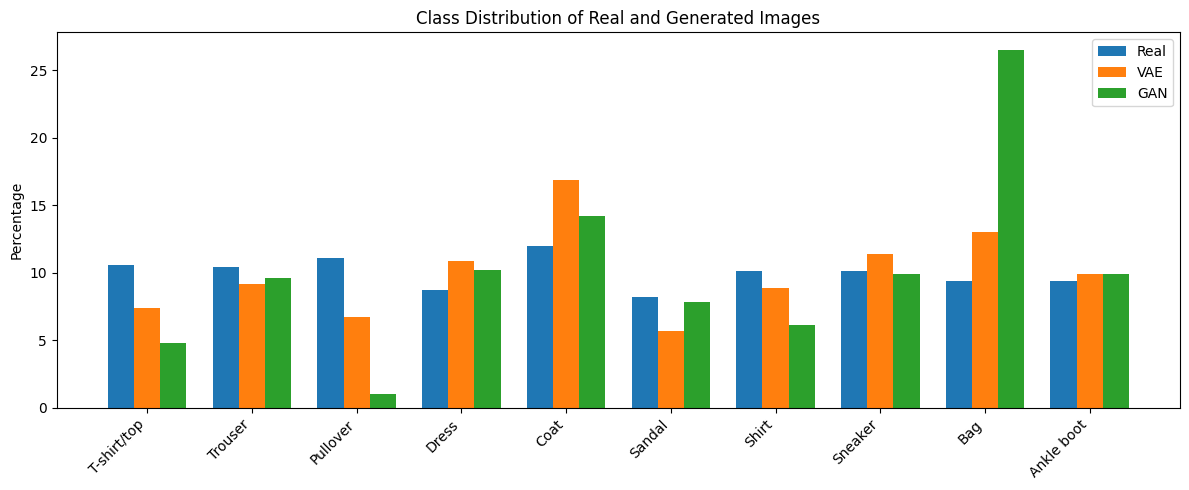

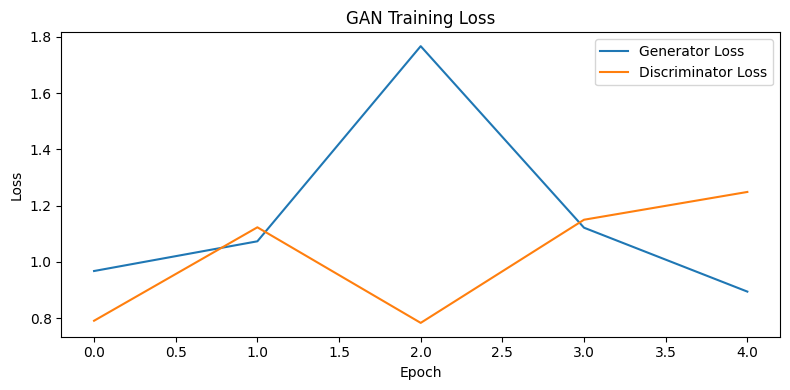

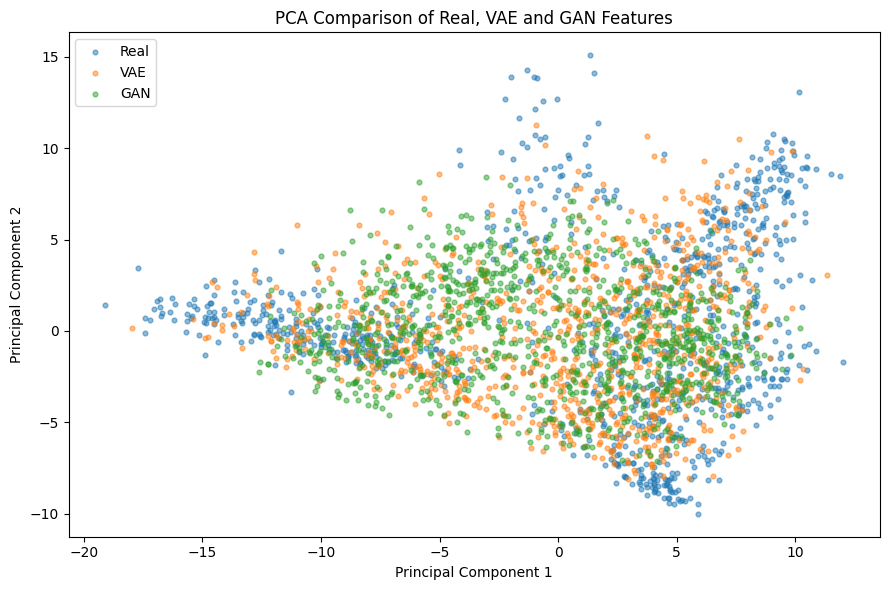


RECOMMENDATION
VAE performs better based on FID and Inception Score. It is the preferred model in this experiment, provided its class distribution and visual quality are acceptable.


In [4]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers
from sklearn.decomposition import PCA
from scipy.linalg import sqrtm

tf.keras.utils.set_random_seed(42)

(x_train,y_train),(x_test,y_test)=tf.keras.datasets.fashion_mnist.load_data()
x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0
x_train=x_train[...,np.newaxis]
x_test=x_test[...,np.newaxis]
train_images=x_train[:30000]
train_labels=y_train[:30000]

classifier_input=tf.keras.Input(shape=(28,28,1))
x=layers.Flatten()(classifier_input)
x=layers.Dense(256,activation="relu")(x)
feature_layer=layers.Dense(128,activation="relu",name="feature_layer")(x)
classifier_output=layers.Dense(10,activation="softmax")(feature_layer)
classifier=tf.keras.Model(classifier_input,classifier_output)
classifier.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
classifier.fit(train_images,train_labels,epochs=3,batch_size=128,validation_split=0.1,verbose=1)
print("Classifier Test Accuracy:",classifier.evaluate(x_test,y_test,verbose=0)[1])

feature_model=tf.keras.Model(inputs=classifier.inputs,outputs=classifier.get_layer("feature_layer").output)

latent_dim=32
encoder_input=tf.keras.Input(shape=(28,28,1))
x=layers.Conv2D(32,3,strides=2,padding="same",activation="relu")(encoder_input)
x=layers.Conv2D(64,3,strides=2,padding="same",activation="relu")(x)
x=layers.Flatten()(x)
x=layers.Dense(128,activation="relu")(x)
z_mean=layers.Dense(latent_dim)(x)
z_log_var=layers.Dense(latent_dim)(x)

def sampling(args):
    mean,log_var=args
    epsilon=tf.random.normal(shape=tf.shape(mean))
    return mean+tf.exp(0.5*log_var)*epsilon

z=layers.Lambda(sampling)([z_mean,z_log_var])
encoder=tf.keras.Model(encoder_input,[z_mean,z_log_var,z])

decoder_input=tf.keras.Input(shape=(latent_dim,))
x=layers.Dense(7*7*64,activation="relu")(decoder_input)
x=layers.Reshape((7,7,64))(x)
x=layers.Conv2DTranspose(64,3,strides=2,padding="same",activation="relu")(x)
x=layers.Conv2DTranspose(32,3,strides=2,padding="same",activation="relu")(x)
decoder_output=layers.Conv2D(1,3,padding="same",activation="sigmoid")(x)
decoder=tf.keras.Model(decoder_input,decoder_output)

class VAE(tf.keras.Model):
    def __init__(self,encoder,decoder):
        super().__init__()
        self.encoder=encoder
        self.decoder=decoder
        self.total_loss_tracker=tf.keras.metrics.Mean(name="loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker]

    def train_step(self,data):
        if isinstance(data,tuple):
            data=data[0]
        with tf.GradientTape() as tape:
            mean,log_var,z=self.encoder(data,training=True)
            reconstruction=self.decoder(z,training=True)
            reconstruction_loss=tf.reduce_mean(tf.reduce_sum(tf.keras.losses.binary_crossentropy(data,reconstruction),axis=(1,2)))
            kl_loss=-0.5*tf.reduce_mean(tf.reduce_sum(1+log_var-tf.square(mean)-tf.exp(log_var),axis=1))
            total_loss=reconstruction_loss+kl_loss
        gradients=tape.gradient(total_loss,self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients,self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        return {"loss":self.total_loss_tracker.result()}

vae=VAE(encoder,decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam(1e-3))
vae.fit(train_images,epochs=5,batch_size=128,verbose=1)

def build_generator():
    inputs=tf.keras.Input(shape=(100,))
    x=layers.Dense(7*7*128)(inputs)
    x=layers.LeakyReLU(negative_slope=0.2)(x)
    x=layers.Reshape((7,7,128))(x)
    x=layers.Conv2DTranspose(128,4,strides=2,padding="same")(x)
    x=layers.LeakyReLU(negative_slope=0.2)(x)
    x=layers.Conv2DTranspose(64,4,strides=2,padding="same")(x)
    x=layers.LeakyReLU(negative_slope=0.2)(x)
    outputs=layers.Conv2D(1,3,padding="same",activation="tanh")(x)
    return tf.keras.Model(inputs,outputs)

def build_discriminator():
    inputs=tf.keras.Input(shape=(28,28,1))
    x=layers.Conv2D(64,4,strides=2,padding="same")(inputs)
    x=layers.LeakyReLU(negative_slope=0.2)(x)
    x=layers.Dropout(0.3)(x)
    x=layers.Conv2D(128,4,strides=2,padding="same")(x)
    x=layers.LeakyReLU(negative_slope=0.2)(x)
    x=layers.Dropout(0.3)(x)
    x=layers.Flatten()(x)
    outputs=layers.Dense(1,activation="sigmoid")(x)
    return tf.keras.Model(inputs,outputs)

generator=build_generator()
discriminator=build_discriminator()

gan_optimizer=tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer=tf.keras.optimizers.Adam(1e-4)
cross_entropy=tf.keras.losses.BinaryCrossentropy()

gan_data=(train_images*2.0)-1.0
gan_dataset=tf.data.Dataset.from_tensor_slices(gan_data).shuffle(10000).batch(128,drop_remainder=True).prefetch(tf.data.AUTOTUNE)

generator_losses=[]
discriminator_losses=[]

@tf.function
def train_gan_step(real_images):
    batch_size=tf.shape(real_images)[0]
    noise=tf.random.normal([batch_size,100])

    with tf.GradientTape() as gen_tape,tf.GradientTape() as disc_tape:
        generated_images=generator(noise,training=True)
        real_output=discriminator(real_images,training=True)
        fake_output=discriminator(generated_images,training=True)

        gen_loss=cross_entropy(tf.ones_like(fake_output),fake_output)
        real_loss=cross_entropy(tf.ones_like(real_output),real_output)
        fake_loss=cross_entropy(tf.zeros_like(fake_output),fake_output)
        disc_loss=real_loss+fake_loss

    gen_gradients=gen_tape.gradient(gen_loss,generator.trainable_variables)
    disc_gradients=disc_tape.gradient(disc_loss,discriminator.trainable_variables)

    gan_optimizer.apply_gradients(zip(gen_gradients,generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients,discriminator.trainable_variables))

    return gen_loss,disc_loss

for epoch in range(5):
    gen_epoch=[]
    disc_epoch=[]
    for real_batch in gan_dataset:
        gl,dl=train_gan_step(real_batch)
        gen_epoch.append(float(gl))
        disc_epoch.append(float(dl))

    generator_losses.append(np.mean(gen_epoch))
    discriminator_losses.append(np.mean(disc_epoch))

    print("GAN Epoch",epoch+1,"Generator Loss:",round(generator_losses[-1],4),"Discriminator Loss:",round(discriminator_losses[-1],4))

vae_samples=decoder.predict(np.random.normal(size=(1000,latent_dim)).astype("float32"),verbose=0)
gan_noise=np.random.normal(size=(1000,100)).astype("float32")
gan_samples=(generator.predict(gan_noise,verbose=0)+1.0)/2.0

vae_samples=np.clip(vae_samples,0,1)
gan_samples=np.clip(gan_samples,0,1)
real_samples=x_test[:1000]

def show_samples(images,title):
    plt.figure(figsize=(10,4))
    for i in range(20):
        plt.subplot(2,10,i+1)
        plt.imshow(images[i].squeeze(),cmap="gray")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_samples(real_samples,"Real Fashion-MNIST Images")
show_samples(vae_samples,"VAE Generated Images")
show_samples(gan_samples,"GAN Generated Images")

def get_features(images):
    images=np.asarray(images,dtype="float32")
    if images.ndim==3:
        images=images[...,np.newaxis]
    return feature_model.predict(images,batch_size=128,verbose=0)

real_features=get_features(real_samples)
vae_features=get_features(vae_samples)
gan_features=get_features(gan_samples)

def calculate_fid(real_features,generated_features):
    mu1=np.mean(real_features,axis=0)
    mu2=np.mean(generated_features,axis=0)
    sigma1=np.cov(real_features,rowvar=False)
    sigma2=np.cov(generated_features,rowvar=False)
    covariance_mean=sqrtm(sigma1@sigma2)
    if not np.isfinite(covariance_mean).all():
        offset=np.eye(sigma1.shape[0])*1e-6
        covariance_mean=sqrtm((sigma1+offset)@(sigma2+offset))
    if np.iscomplexobj(covariance_mean):
        covariance_mean=covariance_mean.real
    difference=mu1-mu2
    fid=difference@difference+np.trace(sigma1+sigma2-2*covariance_mean)
    return float(max(fid,0))

def calculate_inception_score(images,splits=5):
    predictions=classifier.predict(images,batch_size=128,verbose=0)
    scores=[]
    for part in np.array_split(predictions,splits):
        marginal=np.mean(part,axis=0)
        kl=part*(np.log(part+1e-10)-np.log(marginal+1e-10))
        scores.append(np.exp(np.mean(np.sum(kl,axis=1))))
    return float(np.mean(scores))

def calculate_diversity(features):
    return float(np.mean(np.var(features,axis=0)))

def calculate_class_distribution(images):
    predictions=classifier.predict(images,batch_size=128,verbose=0)
    labels=np.argmax(predictions,axis=1)
    counts=np.bincount(labels,minlength=10)
    percentages=counts/len(labels)*100
    return counts,percentages

vae_is=calculate_inception_score(vae_samples)
gan_is=calculate_inception_score(gan_samples)

vae_fid=calculate_fid(real_features,vae_features)
gan_fid=calculate_fid(real_features,gan_features)

real_diversity=calculate_diversity(real_features)
vae_diversity=calculate_diversity(vae_features)
gan_diversity=calculate_diversity(gan_features)

vae_counts,vae_percentages=calculate_class_distribution(vae_samples)
gan_counts,gan_percentages=calculate_class_distribution(gan_samples)
real_counts,real_percentages=calculate_class_distribution(real_samples)

class_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]

results=pd.DataFrame({
    "Metric":["Inception Score","FID","Feature Diversity"],
    "Real":[np.nan,0,real_diversity],
    "VAE":[vae_is,vae_fid,vae_diversity],
    "GAN":[gan_is,gan_fid,gan_diversity]
})

print("\nGENERATIVE MODEL COMPARISON")
print(results.round(4).to_string(index=False))

distribution=pd.DataFrame({
    "Fashion Class":class_names,
    "Real (%)":real_percentages,
    "VAE (%)":vae_percentages,
    "GAN (%)":gan_percentages
})

print("\nCLASS DISTRIBUTION")
print(distribution.round(2).to_string(index=False))

plt.figure(figsize=(12,5))
x=np.arange(10)
width=0.25
plt.bar(x-width,real_percentages,width,label="Real")
plt.bar(x,vae_percentages,width,label="VAE")
plt.bar(x+width,gan_percentages,width,label="GAN")
plt.xticks(x,class_names,rotation=45,ha="right")
plt.ylabel("Percentage")
plt.title("Class Distribution of Real and Generated Images")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plt.plot(generator_losses,label="Generator Loss")
plt.plot(discriminator_losses,label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.tight_layout()
plt.show()

combined_features=np.vstack([real_features,vae_features,gan_features])
pca=PCA(n_components=2)
reduced=pca.fit_transform(combined_features)

plt.figure(figsize=(9,6))
plt.scatter(reduced[:1000,0],reduced[:1000,1],label="Real",alpha=0.5,s=12)
plt.scatter(reduced[1000:2000,0],reduced[1000:2000,1],label="VAE",alpha=0.5,s=12)
plt.scatter(reduced[2000:3000,0],reduced[2000:3000,1],label="GAN",alpha=0.5,s=12)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Comparison of Real, VAE and GAN Features")
plt.legend()
plt.tight_layout()
plt.show()

print("\nRECOMMENDATION")

if gan_fid<vae_fid and gan_is>vae_is:
    print("GAN performs better based on FID and Inception Score. It is the preferred model in this experiment, provided its class distribution and visual quality are acceptable.")
elif vae_fid<gan_fid and vae_is>gan_is:
    print("VAE performs better based on FID and Inception Score. It is the preferred model in this experiment, provided its class distribution and visual quality are acceptable.")
elif gan_fid<vae_fid:
    print("GAN has the lower FID, indicating closer feature statistics to real images. Compare its Inception Score and class distribution before selecting it.")
elif vae_fid<gan_fid:
    print("VAE has the lower FID, indicating closer feature statistics to real images. Compare its Inception Score and class distribution before selecting a model.")
else:
    print("Both models have similar FID. Compare their Inception Scores, diversity, class distributions and generated images before selecting a model.")
